1. 根据课上演示内容，完善以下代码。假设我们想模拟一家电子商务公司的客户交易数据集。我们可以使用numpy和pandas库来生成数据并将其存储在DataFrame中。接下来，我们可以生成一个具有10000行的模拟数据集，其中每行代表一个客户交易：

customer_id
114     265.997273
7452    268.334492
7812    282.150185
4648    287.563867
5085    293.929424
1626    302.442941
3971    312.199655
2111    315.445229
6963    334.877903
5372    338.539486
Name: purchase_amount, dtype: float64


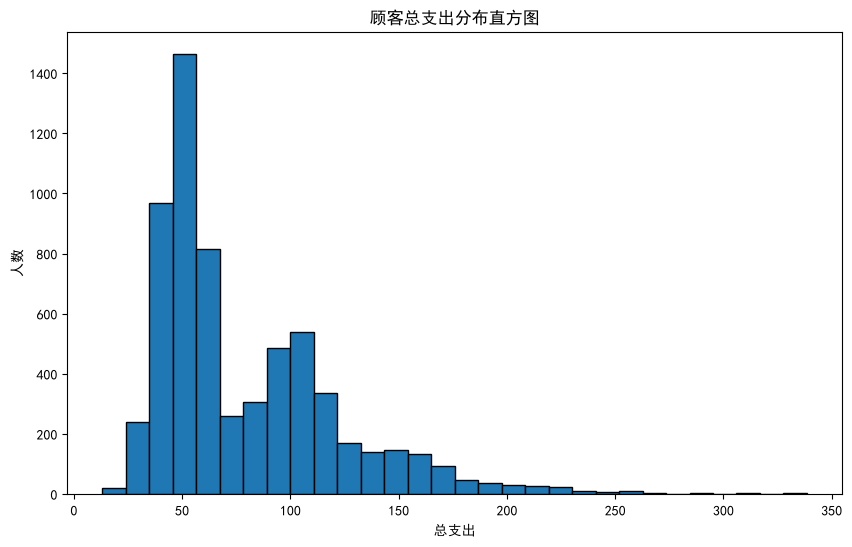

4078
    customer_id  purchase_amount purchase_date product_category  satisfaction
7            97        60.338034    2022-10-23             电子产品           8.8
10         4144        41.008434    2022-03-01               服装           6.8
13          943        52.674863    2022-07-24             电子产品          10.0
15          112        72.783898    2022-01-09               图书           8.4
17         1364        44.520077    2022-04-21               服装           6.2


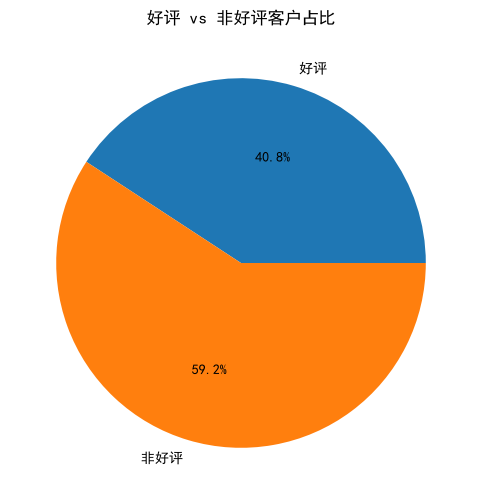

In [1]:
# 添加需要导入的库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 设置随机数种子，保证每次运行生成的数据一致（可复现性）
np.random.seed(123)

# ==============================
# 1. 生成模拟数据
# ==============================

# 随机生成 10000 个顾客ID（范围 1~10000 之间，可能有重复）
customer_ids = np.random.randint(1, 10001, size=10000)


# 随机生成 10000 个购买金额，服从均值 50、标准差 10 的正态分布
purchase_amounts = np.random.normal(50, 10, 10000)


# 随机生成 10000 个购买日期，范围在 2022-01-01 ~ 2022-12-31 之间
start_date = pd.to_datetime('2022-01-01')
rand_days = np.random.randint(0, 365, size=10000)
purchase_dates = start_date + pd.to_timedelta(rand_days, unit='D')

# 随机生成 10000 个商品类别（电子产品/服装/图书）
categories = np.random.choice(['电子产品', '服装', '图书'], size=10000)


# 随机生成 10000 个购物满意度评分（0-10分，保留一位小数）
# 这里使用均匀分布模拟
scores = np.round(np.random.uniform(0, 10, size=10000), 1)


# ==============================
# 2. 组装为 DataFrame
# ==============================

# 把数据整理成 DataFrame（类似数据库表格）
df = pd.DataFrame({
    'customer_id': customer_ids,
    'purchase_amount': purchase_amounts,
    'purchase_date': purchase_dates,
    'product_category': categories,
    'satisfaction': scores
})
df.head()

# ==============================
# 3. 统计分析：每位顾客总支出
# ==============================

# 按 customer_id 分组，汇总每个顾客的总支出
customer_total = df.groupby('customer_id')['purchase_amount'].sum()

# 对总支出进行升序排序（从低到高）
customer_total_sorted = customer_total.sort_values()

# 打印支出总额排名后10的顾客
print(customer_total_sorted.tail(10))


# ==============================
# 4. 可视化：顾客总支出的直方图
# ==============================
plt.figure(figsize=(10, 6))
plt.hist(customer_total_sorted, bins=30, edgecolor='black')
plt.xlabel('总支出')
plt.ylabel('人数')
plt.title('顾客总支出分布直方图')
plt.show()

# ==============================
# 5. 客户分层：好评客户（满意度 6.0~10.0）
# ==============================

# 选定满意度评分为 [6.0, 10.0] 的客户（好评客户）
good = df[(df['satisfaction'] >= 6) & (df['satisfaction'] <= 10)]
print(len(good))
print(good.head())


# ==============================
# 6. 可视化：好评 vs 非好评 客户占比（饼图）
# ==============================
n_good = len(good)
n_bad = len(df) - n_good
plt.figure(figsize=(6, 6))
plt.pie([n_good, n_bad], labels=['好评', '非好评'], autopct='%1.1f%%')
plt.title('好评 vs 非好评客户占比')
plt.show()


2. 根据课上演示内容，完善以下代码。

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.795
Method:                 Least Squares   F-statistic:                     3869.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               0.00
Time:                        16:59:31   Log-Likelihood:                -8317.0
No. Observations:                1000   AIC:                         1.664e+04
Df Residuals:                     998   BIC:                         1.665e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -4535.1009    158.520    -28.609      0.0

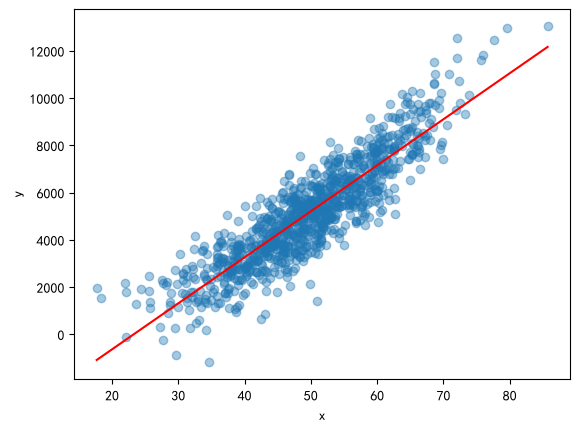

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     2104.
Date:                Sat, 12 Sep 2026   Prob (F-statistic):               0.00
Time:                        16:59:31   Log-Likelihood:                -8282.9
No. Observations:                1000   AIC:                         1.657e+04
Df Residuals:                     997   BIC:                         1.659e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -293.4775    528.139     -0.556      0.5

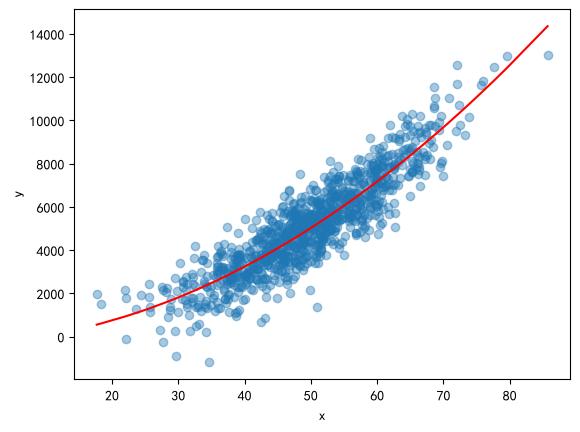

In [2]:
# 导入常用的科学计算库 numpy，用于生成数组、矩阵运算、随机数等
import numpy as np

# 导入 statsmodels 统计建模库，常用于回归分析、假设检验、时间序列建模等
import statsmodels.api as sm

# 导入 matplotlib 的 pyplot 模块，用于绘图和数据可视化
import matplotlib.pyplot as plt

# ==============================
# 1) 生成数据
# ==============================

# 设置随机数“种子”，让后续所有由 NumPy 旧版随机模块(np.random.*)生成的随机数可复现
# 只要种子相同(这里是 123)，每次运行得到的随机序列就完全一样；
# 如果不设置或更换种子，则每次运行都会得到不同的随机数序列。
np.random.seed(123)

# 从正态分布 N(μ=50, σ=10) 中生成 1000 个样本，作为自变量 x
# loc 对应均值 μ，scale 对应标准差 σ，size 表示样本数量或形状
x = np.random.normal(loc=50, scale=10, size=1000)

# 构造因变量 y：设真实关系为 y = 2 * x^2 + ε
# 注意：Python 中幂运算是 ** 而不是 ^（^ 是按位异或）
# 其中噪声 ε ~ N(0, 1000)，即均值为 0、标准差为 1000 的高斯噪声
y = 2 * (x ** 2) + np.random.normal(loc=0, scale=1000, size=1000)


# ==============================
# 2) 线性模型：y ~ 1 + x
# ==============================

# 将常数项添加到预测变量（截距项）
X = sm.add_constant(x)

# 使用线性回归模型进行拟合数据
model = sm.OLS(y, X).fit()

# 打印模型相关信息（摘要）
print(model.summary())

# 绘制数据和线性回归线
plt.scatter(x, y, alpha=0.4)
order = np.argsort(x)
plt.plot(x[order], model.predict(X[order]), color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

#######################################
#####这个拟合模型是否合理？############
###结合AI工具解读回归分析结果##########
#######################################


# ==============================
# 3) 二次模型（含平方项）：y ~ 1 + x + x^2
# ==============================

# 尝试用 x 的平方项，构建新的模型（多项式回归的一种）
x2 = x ** 2
# 拼接成设计矩阵：[const, x, x^2]
X_quad = np.column_stack([np.ones_like(x), x, x2])

# 使用二次项模型进行拟合数据
model_quad = sm.OLS(y, X_quad).fit()

# 打印模型相关信息（摘要）
print(model_quad.summary())

# 绘制数据和二次回归曲线
plt.scatter(x, y, alpha=0.4)
xs = np.sort(x)
ys = model_quad.params[0] + model_quad.params[1] * xs + model_quad.params[2] * xs ** 2
plt.plot(xs, ys, color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

#######################################
#####这个拟合模型是否合理？############
###结合AI工具解读回归分析结果##########
#######################################


在此对两个不同模型效果进行比较，可以用AI工具读取模型相关信息

3. 图像向量空间与“零均值图像”子空间

## 场景
把一张 $8\times 8$ 的灰度小图拉平成向量 $\mathbf{x}\in\mathbb{R}^{64}$。  
令整空间 $\mathcal{V}=\mathbb{R}^{64}$。定义集合
$$
\mathcal{U}=\{\mathbf{x}\in\mathbb{R}^{64}\mid \mathbf{1}^\top \mathbf{x}=0\},
$$

即所有 **像素和为 0（零均值）** 的图像向量。

### 任务
1. **证明**：$\mathcal{U}$ 是 $\mathcal{V}$ 的一个子空间。  
2. 用 **Python** 随机生成几张“图像”向量，数值上**验证**子空间的封闭性（加法、数乘）。  
3. 随机取三张零均值图像 $\mathbf{x}_1,\mathbf{x}_2,\mathbf{x}_3\in\mathcal{U}$，判断它们是否**线性无关**。  
4. 给定任意图像向量 $\mathbf{y}\in\mathbb{R}^{64}$，写出其在 $\mathcal{U}$ 上的**正交投影**（也就是去均值），并用代码实现。  

---


## 提示 1：证明子空间
- 子空间必须满足三个条件：  
  1. **非空**（至少包含零向量）；  
  2. **加法封闭**；  
  3. **数乘封闭**。  
- 可以直接代入 $\mathbf{1}^\top \mathbf{x}=0$ 来检验。  

---

## 提示 2：Python 验证封闭性
- 用 `numpy` 生成随机向量，再减去均值得到“零均值向量”。  
- 用 `.sum()` 检查是不是接近 0（浮点误差允许 `1e-15` 量级）。  
- 分别验证：  
  - 两个零均值向量相加，结果是否还是零均值；  
  - 一个零均值向量乘以常数，结果是否还是零均值。  

---

## 提示 3：线性无关性
- 将多个零均值向量拼成矩阵 `A = [x1, x2, x3]`。  
- 用 `np.linalg.matrix_rank(A)` 计算秩。  
- 判断标准：  
  - $\mathrm{rank}(A) = 3 \;\Rightarrow\;$ 三个向量线性无关；  
  - $\mathrm{rank}(A) < 3 \;\Rightarrow\;$ 三个向量线性相关。  

---

## 提示 4：正交投影（去均值）
- 思考：$\mathcal{U}$ 是所有“零均值向量”的集合。  
- 对任意 $\mathbf{y}$，要找它在 $\mathcal{U}$ 中的投影，就是“减去均值部分”。  
- 公式：
  $$
  \mathrm{Proj}_{\mathcal{U}}(\mathbf{y}) = \mathbf{y} - \frac{\sum_i y_i}{64}\cdot \mathbf{1}
  $$
- 编程思路：`projU_y = y - y.mean()`。  
- 应用场景：这是**去 DC 分量**，在信号处理、图像分析里很常见，比如人脸识别前的图像标准化。



---


### 3.1 证明 $\mathcal{U}$ 是 $\mathcal{V}$ 的子空间
记 $\mathbf{1}=(1,\cdots,1)^\top\in \mathbb{R}^{64}$，则 $\mathcal{U}=\{\mathbf{x}\mid \mathbf{1}^\top\mathbf{x}=0\}$。

（1）非空：$\mathbf{0}$ 的分量和为 0，所以 $\mathbf{0}\in\mathcal{U}$，$\mathcal{U}$ 非空。

（2）加法封闭：任取 $\mathbf{x},\mathbf{y}\in\mathcal{U}$，则 $\mathbf{1}^\top\mathbf{x}=0$ 且 $\mathbf{1}^\top\mathbf{y}=0$，于是 $\mathbf{1}^\top(\mathbf{x}+\mathbf{y})=\mathbf{1}^\top\mathbf{x}+\mathbf{1}^\top\mathbf{y}=0$，所以 $\mathbf{x}+\mathbf{y}\in\mathcal{U}$。

（3）数乘封闭：任取 $\mathbf{x}\in\mathcal{U}$，$a\in\mathbb{R}$，则 $\mathbf{1}^\top(a\mathbf{x})=a(\mathbf{1}^\top\mathbf{x})=0$，所以 $a\mathbf{x}\in\mathcal{U}$。

由（1）（2）（3）可知 $\mathcal{U}$ 是 $\mathbb{R}^{64}$ 的子空间，维数为 63。


In [3]:
import numpy as np
np.random.seed(7)
a = np.random.randn(64)
a = a - a.mean()
b = np.random.randn(64)
b = b - b.mean()
print(a.sum())
print(b.sum())
c = a + b
print(c.sum())
d = 3.2 * a
print(d.sum())
print(abs(c.sum()) < 1e-10)
print(abs(d.sum()) < 1e-10)
x1 = np.random.randn(64)
x1 = x1 - x1.mean()
x2 = np.random.randn(64)
x2 = x2 - x2.mean()
x3 = np.random.randn(64)
x3 = x3 - x3.mean()
A = np.column_stack((x1, x2, x3))
r = np.linalg.matrix_rank(A)
print(r)
if r == 3:
    print('线性无关')
else:
    print('线性相关')
y = np.random.rand(64) * 255
p = y - y.mean()
print(y.mean())
print(p.mean())
print(p.sum())


-4.440892098500626e-16
8.881784197001252e-16
-2.6645352591003757e-15
-9.769962616701378e-15
True
True
3
线性无关
127.22184084122614
8.881784197001252e-15
5.684341886080801e-13


线性模型 R-squared 约为 0.795，二次模型 R-squared 约为 0.808，二次模型更高一些。二次项系数 p 值接近 0，通过显著性检验，而线性模型把曲线关系强行用直线拟合，截距为很大的负数，明显不合理。从散点图也能看出 y 和 x 是开口向上的抛物线关系，所以二次模型更合理，线性模型不合理。
